# Resultados del piloto de tópicos: 5.000 reseñas

Este piloto comprueba el comportamiento de G0, G3 y R2 al ampliar la muestra de 1.000 a **5.000 reseñas**. Los modelos ya se ejecutaron desde el CLI, mediante ZenML y MLflow. Aquí leemos sus artefactos para comparar cobertura, tamaños, recursos y ejemplos. No ajustamos modelos ni generamos embeddings.

G0 usa selección `eom` de HDBSCAN y G3 usa `leaf`. Ambos representan sus grupos con c-TF-IDF. R2 aplica KeyBERTInspired + MMR al G3 del piloto, conservando las pertenencias. La revisión es exploratoria y no demuestra exactitud sobre las 84.479 reseñas del corpus.


## 1. Verificando el protocolo y los resultados

Usamos identidades explícitas, sin buscar la última ejecución. Las funciones de lectura y comparación son las mismas que utiliza el CLI. El protocolo conserva las entradas, versiones y límites del experimento.


In [1]:
import json
import os
from datetime import datetime, timezone
from html import escape
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

from voc.datasets.shared.manifest import file_hash
from voc.embeddings.shared.contracts import canonical_json
from voc.topics import read_topics
from voc.topics.comparison import compare_assignments, review_sample
from voc_ml.topics.corpus import inspect_pilot
from voc_ml.topics.store import TopicRunStore

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/voc").is_dir() and (p / "pyproject.toml").is_file())
store = TopicRunStore(os.environ.get("VOC_DATA_DIR", REPO / "data"))
STUDY_ID = "55822245-4bb3-4f97-89ac-58d536bb2fed"
PROTOCOL_SHA256 = "5a775a55b505ea4e7f7d12b1f5144233f61d2fb46a1770e76786b3bef15dcd7c"
REFERENCES = {
    "G0": {"run_id": "181a13d1-8c02-4a57-8666-83065e6ec43f",
           "manifest_sha256": "e692126070cbaed0200d80a9c802e33ade08047582133e1f36cb7569741dafb7"},
    "G3": {"run_id": "580c8f51-b4b0-4771-9bcb-6ba6e5fbe9e6",
           "manifest_sha256": "d503ddf16e9ae7a4557f50ac690a870c5b09a68694ded0dfa51da7230346c747"},
    "R2": {"run_id": "49c66f80-29fc-44a6-9a2d-f584721c9d59",
           "manifest_sha256": "47f114cd2d7cd85dd3d678d5e35d14d4962bb599a49f7518f4df427117818bcb"},
}
study = inspect_pilot(store=store)
assert study["study_id"] == STUDY_ID
assert study["protocol_sha256"] == PROTOCOL_SHA256
bundles, runs = {}, {}
for variant, ref in REFERENCES.items():
    entry = study["entries"][variant]
    assert entry["state"] == "completed"
    assert all(entry[key] == value for key, value in ref.items())
    bundles[variant] = read_topics(store.directory(ref["run_id"]) / "release",
                                  manifest_sha256=ref["manifest_sha256"])
    runs[variant] = store.load(ref["run_id"])
    assert runs[variant]["separate_process_read"] == "passed"
    assert runs[variant]["corpus_protocol_sha256"] == PROTOCOL_SHA256
print("Tres releases verificados. Filas por resultado:", len(bundles["G0"].reviews))
print("Protocolo:", PROTOCOL_SHA256)


Tres releases verificados. Filas por resultado: 5000
Protocolo: 5a775a55b505ea4e7f7d12b1f5144233f61d2fb46a1770e76786b3bef15dcd7c


## 2. Cobertura y granularidad

Un mayor número de tópicos no demuestra mayor utilidad. Observa cuántas reseñas reciben asignación y cómo cambian los tamaños. Los registros con tópico `-1` siguen en el resultado, aunque no pertenezcan a un grupo identificado.


,rows,topic_count,unassigned_rows,unassigned_fraction,minimum_topic_size,median_topic_size,maximum_topic_size
variant,,,,,,,
G0,5000,164,1052,0.2104,10,19.5,199
G3,5000,173,1258,0.2516,10,19.0,60
R2,5000,173,1258,0.2516,10,19.0,60


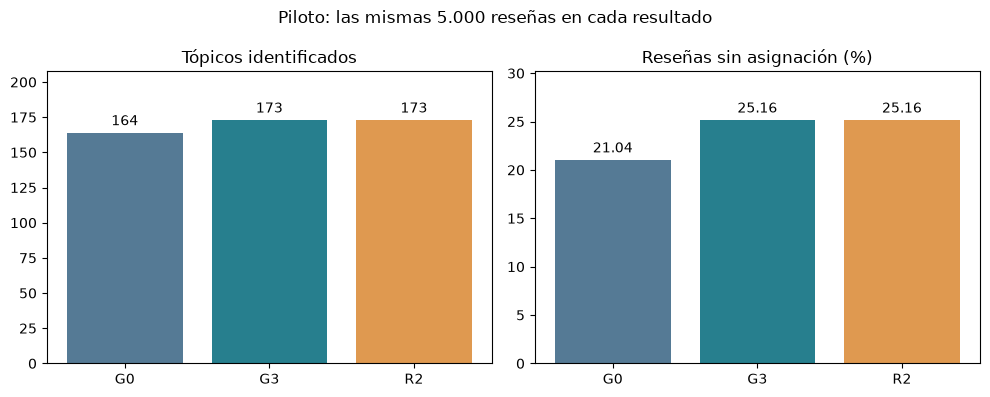

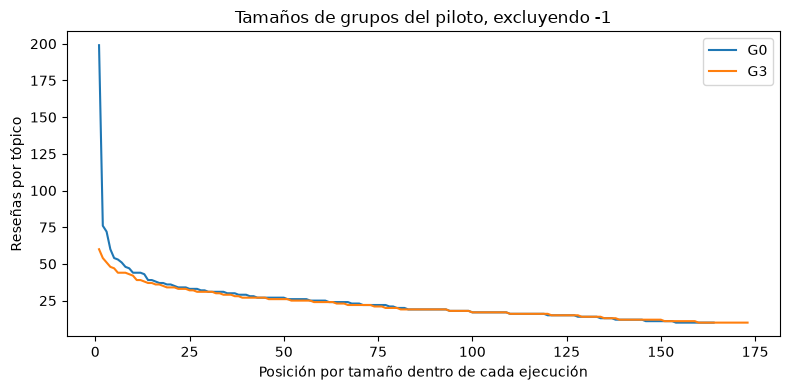

In [2]:
summary = pd.DataFrame(study["summaries"]).set_index("variant").loc[list(REFERENCES)]
display(summary[["rows", "topic_count", "unassigned_rows", "unassigned_fraction",
                 "minimum_topic_size", "median_topic_size", "maximum_topic_size"]])
figures = {}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, column, title, scale in [
    (axes[0], "topic_count", "Tópicos identificados", 1),
    (axes[1], "unassigned_fraction", "Reseñas sin asignación (%)", 100),
]:
    values = summary[column] * scale
    bars = ax.bar(summary.index, values, color=["#557a95", "#277f8e", "#df9950"])
    ax.bar_label(bars, labels=[f"{x:.2f}" if scale == 100 else str(int(x)) for x in values], padding=3)
    ax.set_title(title)
    ax.set_ylim(0, values.max() * 1.2)
fig.suptitle("Piloto: las mismas 5.000 reseñas en cada resultado")
fig.tight_layout()
figures["piloto-cobertura"] = fig
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for offset, variant in enumerate(["G0", "G3"]):
    sizes = np.sort(summary.loc[variant, "topic_sizes"])[::-1]
    ax.plot(np.arange(1, len(sizes) + 1), sizes, label=variant)
ax.set(xlabel="Posición por tamaño dentro de cada ejecución", ylabel="Reseñas por tópico",
       title="Tamaños de grupos del piloto, excluyendo -1")
ax.legend()
fig.tight_layout()
figures["piloto-tamanos"] = fig
plt.show()


## 3. Comparando pertenencias

El ARI mide concordancia entre particiones, no calidad semántica. Una comparación incluye `-1` como un grupo. La otra considera únicamente las reseñas asignadas por ambos resultados y declara su denominador. Los números de tópico no identifican el mismo tema entre G0 y G3.

En R2 verificamos una condición diferente: las asignaciones, coordenadas y referencias de evidencia deben conservarse exactamente respecto a G3.


In [3]:
comparisons = pd.DataFrame([
    {"comparison": "G0 → G3", **compare_assignments(bundles["G0"], bundles["G3"])},
    {"comparison": "G3 → R2", **compare_assignments(bundles["G3"], bundles["R2"])},
])
display(comparisons.drop(columns="unassigned_policy"))
assert bundles["G3"].assignments.equals(bundles["R2"].assignments)
assert np.array_equal(bundles["G3"].coordinates, bundles["R2"].coordinates)
assert {t["topic_id"]: t["evidence_ids"] for t in bundles["G3"].topics} == {
    t["topic_id"]: t["evidence_ids"] for t in bundles["R2"].topics
}
print("R2 conserva pertenencias, coordenadas y evidencia de G3.")


,comparison,rows,ari_including_unassigned,ari_assigned_intersection,assigned_intersection_rows,became_assigned,became_unassigned
0,G0 → G3,5000,0.818862,0.949108,3742,0,206
1,G3 → R2,5000,1.000000,1.000000,3742,0,0


R2 conserva pertenencias, coordenadas y evidencia de G3.


## 4. Recursos observados

Distinguimos el RSS del worker, el RSS sumado de los procesos de la operación y el consumo del cgroup del contenedor. El segundo puede contar páginas compartidas más de una vez. El tercero también incluye servicios y kernels ajenos a ese ajuste. No deben sumarse.

La supervisión toma muestras y cancela si se supera un umbral. No impone un límite duro de memoria. Estas medidas describen el piloto, sin extrapolar linealmente al corpus completo.


,preparation_seconds,worker_seconds,export_seconds,total_seconds,worker_rss_gib,group_rss_gib,cgroup_gib
variant,,,,,,,
G0,1.524,18.571,0.118,24.440,1.071,1.692,5.632
G3,1.524,16.693,0.115,21.967,1.074,1.695,5.502
R2,0.073,16.293,0.134,20.168,1.582,2.183,6.298


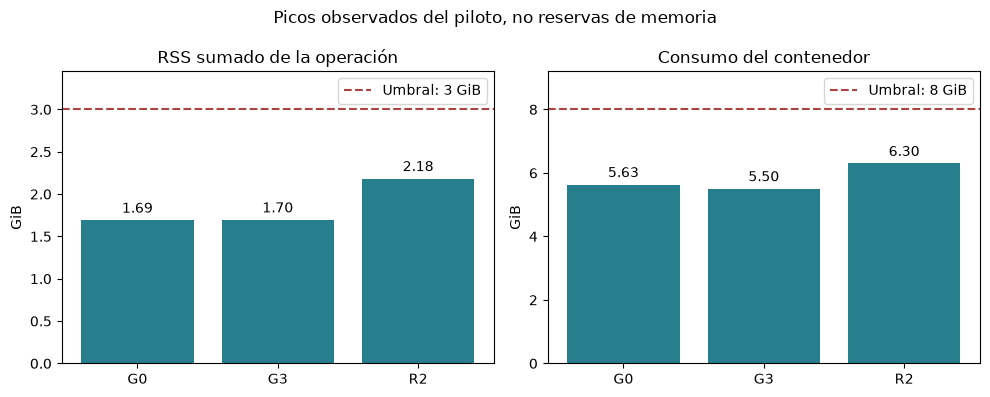

In [4]:
resource_rows = []
for variant, run in runs.items():
    supervision = run["supervision"]
    resource_rows.append({
        "variant": variant,
        "preparation_seconds": run["preparation_seconds"],
        "worker_seconds": run["worker_wall_seconds"],
        "export_seconds": run["export_seconds"],
        "total_seconds": supervision["wall_seconds"],
        "worker_rss_gib": run["fit"]["peak_worker_rss_bytes"] / 2**30,
        "group_rss_gib": supervision["peak_group_rss_bytes"] / 2**30,
        "cgroup_gib": supervision["peak_cgroup_bytes"] / 2**30,
    })
resources = pd.DataFrame(resource_rows).set_index("variant")
display(resources.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, column, limit, label in [
    (axes[0], "group_rss_gib", 3, "RSS sumado de la operación"),
    (axes[1], "cgroup_gib", 8, "Consumo del contenedor"),
]:
    bars = ax.bar(resources.index, resources[column], color="#277f8e")
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.axhline(limit, linestyle="--", color="#ac4343", label=f"Umbral: {limit} GiB")
    ax.set(title=label, ylabel="GiB", ylim=(0, limit * 1.15))
    ax.legend()
fig.suptitle("Picos observados del piloto, no reservas de memoria")
fig.tight_layout()
figures["piloto-memoria"] = fig
plt.show()


## 5. Revisando palabras y reseñas completas

La pauta conserva los tres grupos mayores y hasta tres adicionales seleccionados con semilla 42. Muestra hasta tres textos distintos de evidencia por grupo. No selecciona ejemplos porque favorezcan una variante.

Primero revisa G3 y R2 sobre los mismos grupos y reseñas. Observa si las palabras aluden a una funcionalidad, si concuerdan con el texto y si siguen siendo genéricas. Una palabra como «transferencia» puede ayudar a interpretar el grupo, pero no demuestra que todas sus reseñas traten ese asunto. Los ejemplos no sustituyen la revisión de todos los miembros.


In [5]:
reviews = {key: review_sample(bundles[key], seed=42) for key in ["G0", "G3"]}

def paragraph(text):
    return '<p style="white-space:pre-wrap;overflow-wrap:anywhere">' + escape(str(text)) + '</p>'

def show_topic(topic, variant, refined=None):
    content = f"<h3>{escape(variant)} · tópico {topic['topic_id']} · {topic['size']} reseñas</h3>"
    content += "<b>c-TF-IDF</b>" + paragraph(", ".join(k["term"] for k in topic["keywords"]))
    if refined is not None:
        content += "<b>KeyBERTInspired + MMR</b>" + paragraph(", ".join(k["term"] for k in refined["keywords"]))
    for evidence in topic["evidence"]:
        content += "<b>ID:</b> " + escape(evidence["record_id"]) + paragraph(evidence["model_text"])
    display(HTML(content + "<hr>"))

for topic in reviews["G3"]["topics"]:
    show_topic(topic, "G3 / R2", bundles["R2"].topic(topic["topic_id"]))


### Contrastando con G0 y con las reseñas sin asignación

La revisión de G0 aplica la misma pauta, pero sus grupos son distintos. Después lee cinco casos sin asignación de G3 para reconocer qué tipo de información queda fuera de sus tópicos.


In [6]:
for topic in reviews["G0"]["topics"]:
    show_topic(topic, "G0")

lookup = bundles["G3"].reviews.set_index("record_id")
display(HTML("<h3>G3: cinco reseñas sin asignación</h3>"))
for record_id in reviews["G3"]["unassigned_ids"]:
    display(HTML("<b>ID:</b> " + escape(record_id) + paragraph(lookup.loc[record_id, "model_text"])))


## 6. Registrando la revisión

Completa autor y observaciones solo después de leer los ejemplos. Señala si G3/R2 ofrece suficiente especificidad para continuar con los parámetros fijados, y qué limitaciones encontraste. No es necesario asignar puntuaciones. Las notas no habilitan automáticamente el procesamiento completo.


In [7]:
REVIEW_FILE = store.root / "reports/topics/corpus/pilot-review.json"
review = json.loads(REVIEW_FILE.read_text()) if REVIEW_FILE.exists() else {
    "study_id": STUDY_ID,
    "protocol_sha256": PROTOCOL_SHA256,
    "reviewer": None,
    "observations": None,
    "decision": None,
    "scope": "revisión exploratoria de ejemplos fijados, no evaluación exhaustiva",
}
assert review["study_id"] == STUDY_ID and review["protocol_sha256"] == PROTOCOL_SHA256
# Completa estos campos o comparte tus observaciones en el chat.
# review["reviewer"] = "..."
# review["observations"] = "..."
# review["decision"] = "..."
print(json.dumps(review, ensure_ascii=False, indent=2))


{
  "study_id": "55822245-4bb3-4f97-89ac-58d536bb2fed",
  "protocol_sha256": "5a775a55b505ea4e7f7d12b1f5144233f61d2fb46a1770e76786b3bef15dcd7c",
  "reviewer": null,
  "observations": null,
  "decision": null,
  "scope": "revisión exploratoria de ejemplos fijados, no evaluación exhaustiva"
}


## 7. Exportando evidencia para el artículo

Exportamos las tablas y figuras para preparar el reporte. Los ejemplos y las notas privadas permanecen bajo `data/`.


In [8]:
folder = store.root / "reports/topics/corpus" / STUDY_ID / (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8]
)
folder.mkdir(parents=True, exist_ok=False)
summary.drop(columns=["topic_sizes", "supervision"], errors="ignore").to_csv(folder / "resumen.csv")
resources.to_csv(folder / "recursos.csv")
comparisons.to_csv(folder / "comparaciones.csv", index=False)
for name, figure in figures.items():
    figure.savefig(folder / f"{name}.png", dpi=180, bbox_inches="tight")
    figure.savefig(folder / f"{name}.pdf", bbox_inches="tight")
(folder / "ejemplos-privados.json").write_bytes(canonical_json(reviews))
(folder / "revision.json").write_bytes(canonical_json(review))
if all(isinstance(review.get(k), str) and review[k].strip()
       for k in ["reviewer", "observations", "decision"]):
    REVIEW_FILE.parent.mkdir(parents=True, exist_ok=True)
    REVIEW_FILE.write_bytes(canonical_json(review))
provenance = {
    "study_id": STUDY_ID, "protocol_sha256": PROTOCOL_SHA256,
    "population_scope": "pilot-5000", "references": REFERENCES,
    "notebook": "reports/topics/resultados-del-piloto.ipynb",
    "notebook_sha256": file_hash(REPO / "reports/topics/resultados-del-piloto.ipynb"),
    "files": {p.name: {"sha256": file_hash(p), "bytes": p.stat().st_size}
              for p in sorted(folder.iterdir()) if p.is_file()},
}
(folder / "manifest.json").write_bytes(canonical_json(provenance))
print("Evidencia exportada:", folder)


Evidencia exportada: /workspace/data/reports/topics/corpus/55822245-4bb3-4f97-89ac-58d536bb2fed/20261103T201916Z-ffd2e281


## Conclusión

El piloto separa viabilidad operativa y utilidad de los tópicos. Los recursos medidos permiten plantear el siguiente presupuesto, mientras las palabras y reseñas ayudan a detectar grupos demasiado genéricos o pérdidas de cobertura. El procesamiento completo requiere fijar su protocolo y ejecutarlo desde el CLI. Esta libreta no lo inicia ni reemplaza los resultados anteriores de 1.000 reseñas.
